Chuẩn bị: đọc dữ liệu

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

print("Lê Anh Pha - 6451071056")

data = pd.read_csv('winequality-red.csv')
print(data.shape)       # phải ra (1599, 12)
data = data.dropna()
data.info()

Lê Anh Pha - 6451071056
(1599, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


Câu 3: Pearson

Lê Anh Pha - 6451071056


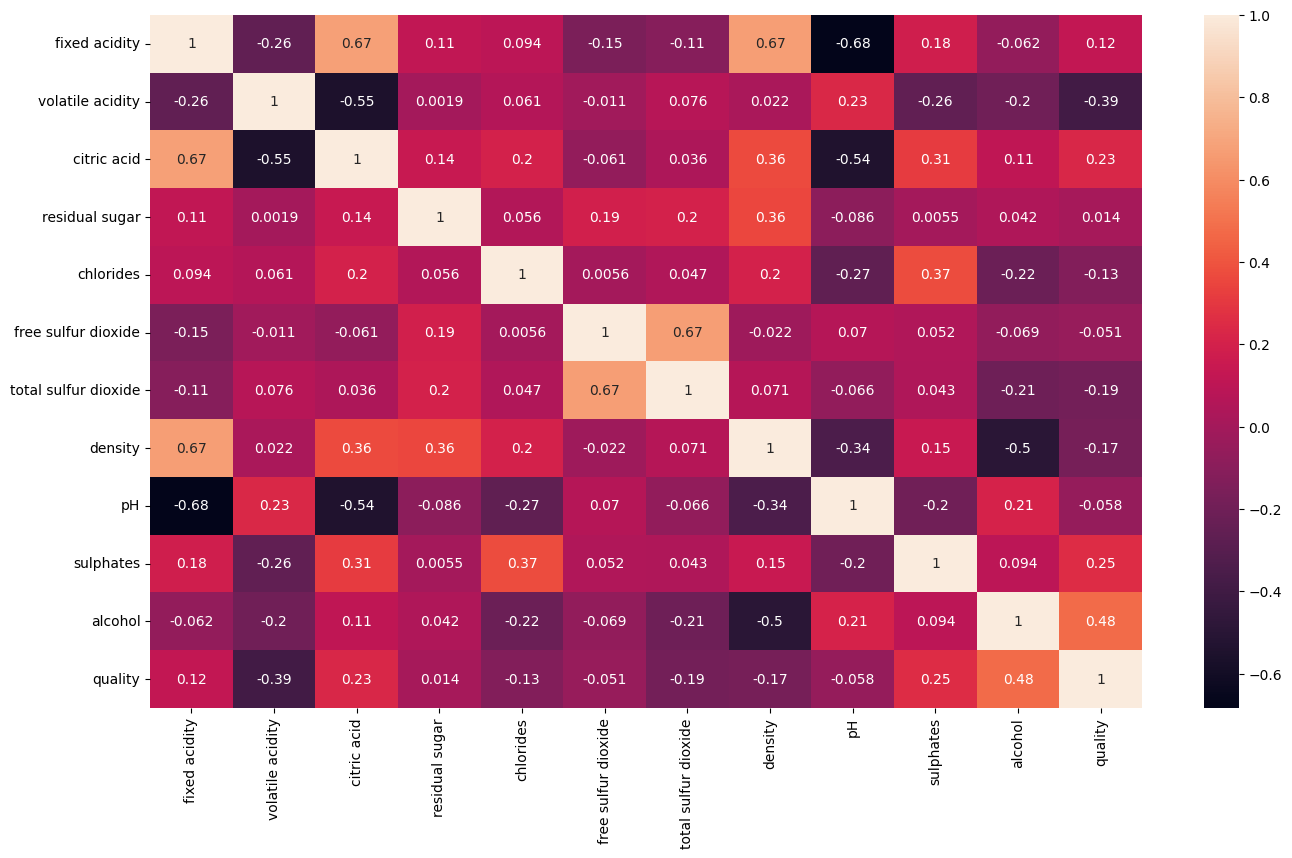

In [3]:
print("Lê Anh Pha - 6451071056")

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method='pearson'), annot=True)
plt.show()
# Nhận xét: chỉ loại cột nếu có cặp tương đồng rất cao (ví dụ > 0.8-0.9).
# Nếu không có cặp nào thì ghi "không cần loại bỏ cột nào".

Câu 4: Tách thuộc tính và nhãn

In [4]:
print("Lê Anh Pha - 6451071056")

features = data.drop('quality', axis=1)
labels = data['quality']
print(features.shape, labels.shape)
print(labels.value_counts().sort_index())

Lê Anh Pha - 6451071056
(1599, 11) (1599,)
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


Câu 5: One-hot

In [5]:
print("Lê Anh Pha - 6451071056")

cat_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Cột không phải số:", list(cat_cols))      # kết quả rỗng: không có cột nào cần one-hot

features_onehot = pd.get_dummies(features, columns=cat_cols)   # không đổi gì nếu rỗng
print(features_onehot.shape)

Lê Anh Pha - 6451071056
Cột không phải số: []
(1599, 11)


Câu 6: Chia 70% huấn luyện, 30% kiểm thử

In [6]:
print("Lê Anh Pha - 6451071056")

X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)

Lê Anh Pha - 6451071056
(1119, 11) (480, 11)


Câu 7: Cây ID3

Lê Anh Pha - 6451071056
Accuracy: 0.5833333333333334
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.08      0.12      0.10        17
           5       0.70      0.66      0.68       195
           6       0.60      0.60      0.60       200
           7       0.43      0.46      0.44        61
           8       0.25      0.17      0.20         6

    accuracy                           0.58       480
   macro avg       0.34      0.33      0.34       480
weighted avg       0.59      0.58      0.59       480



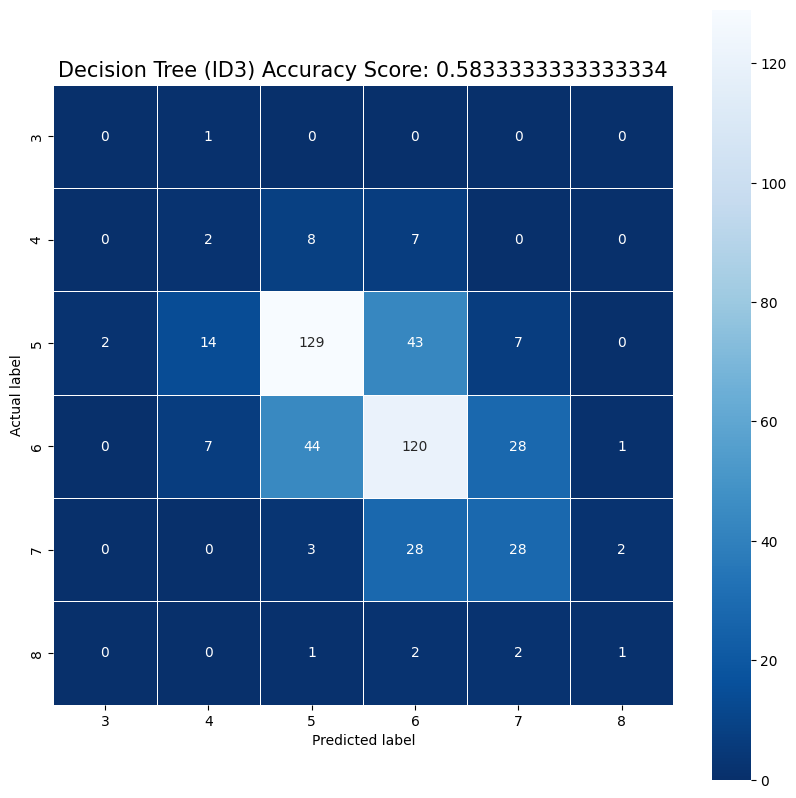

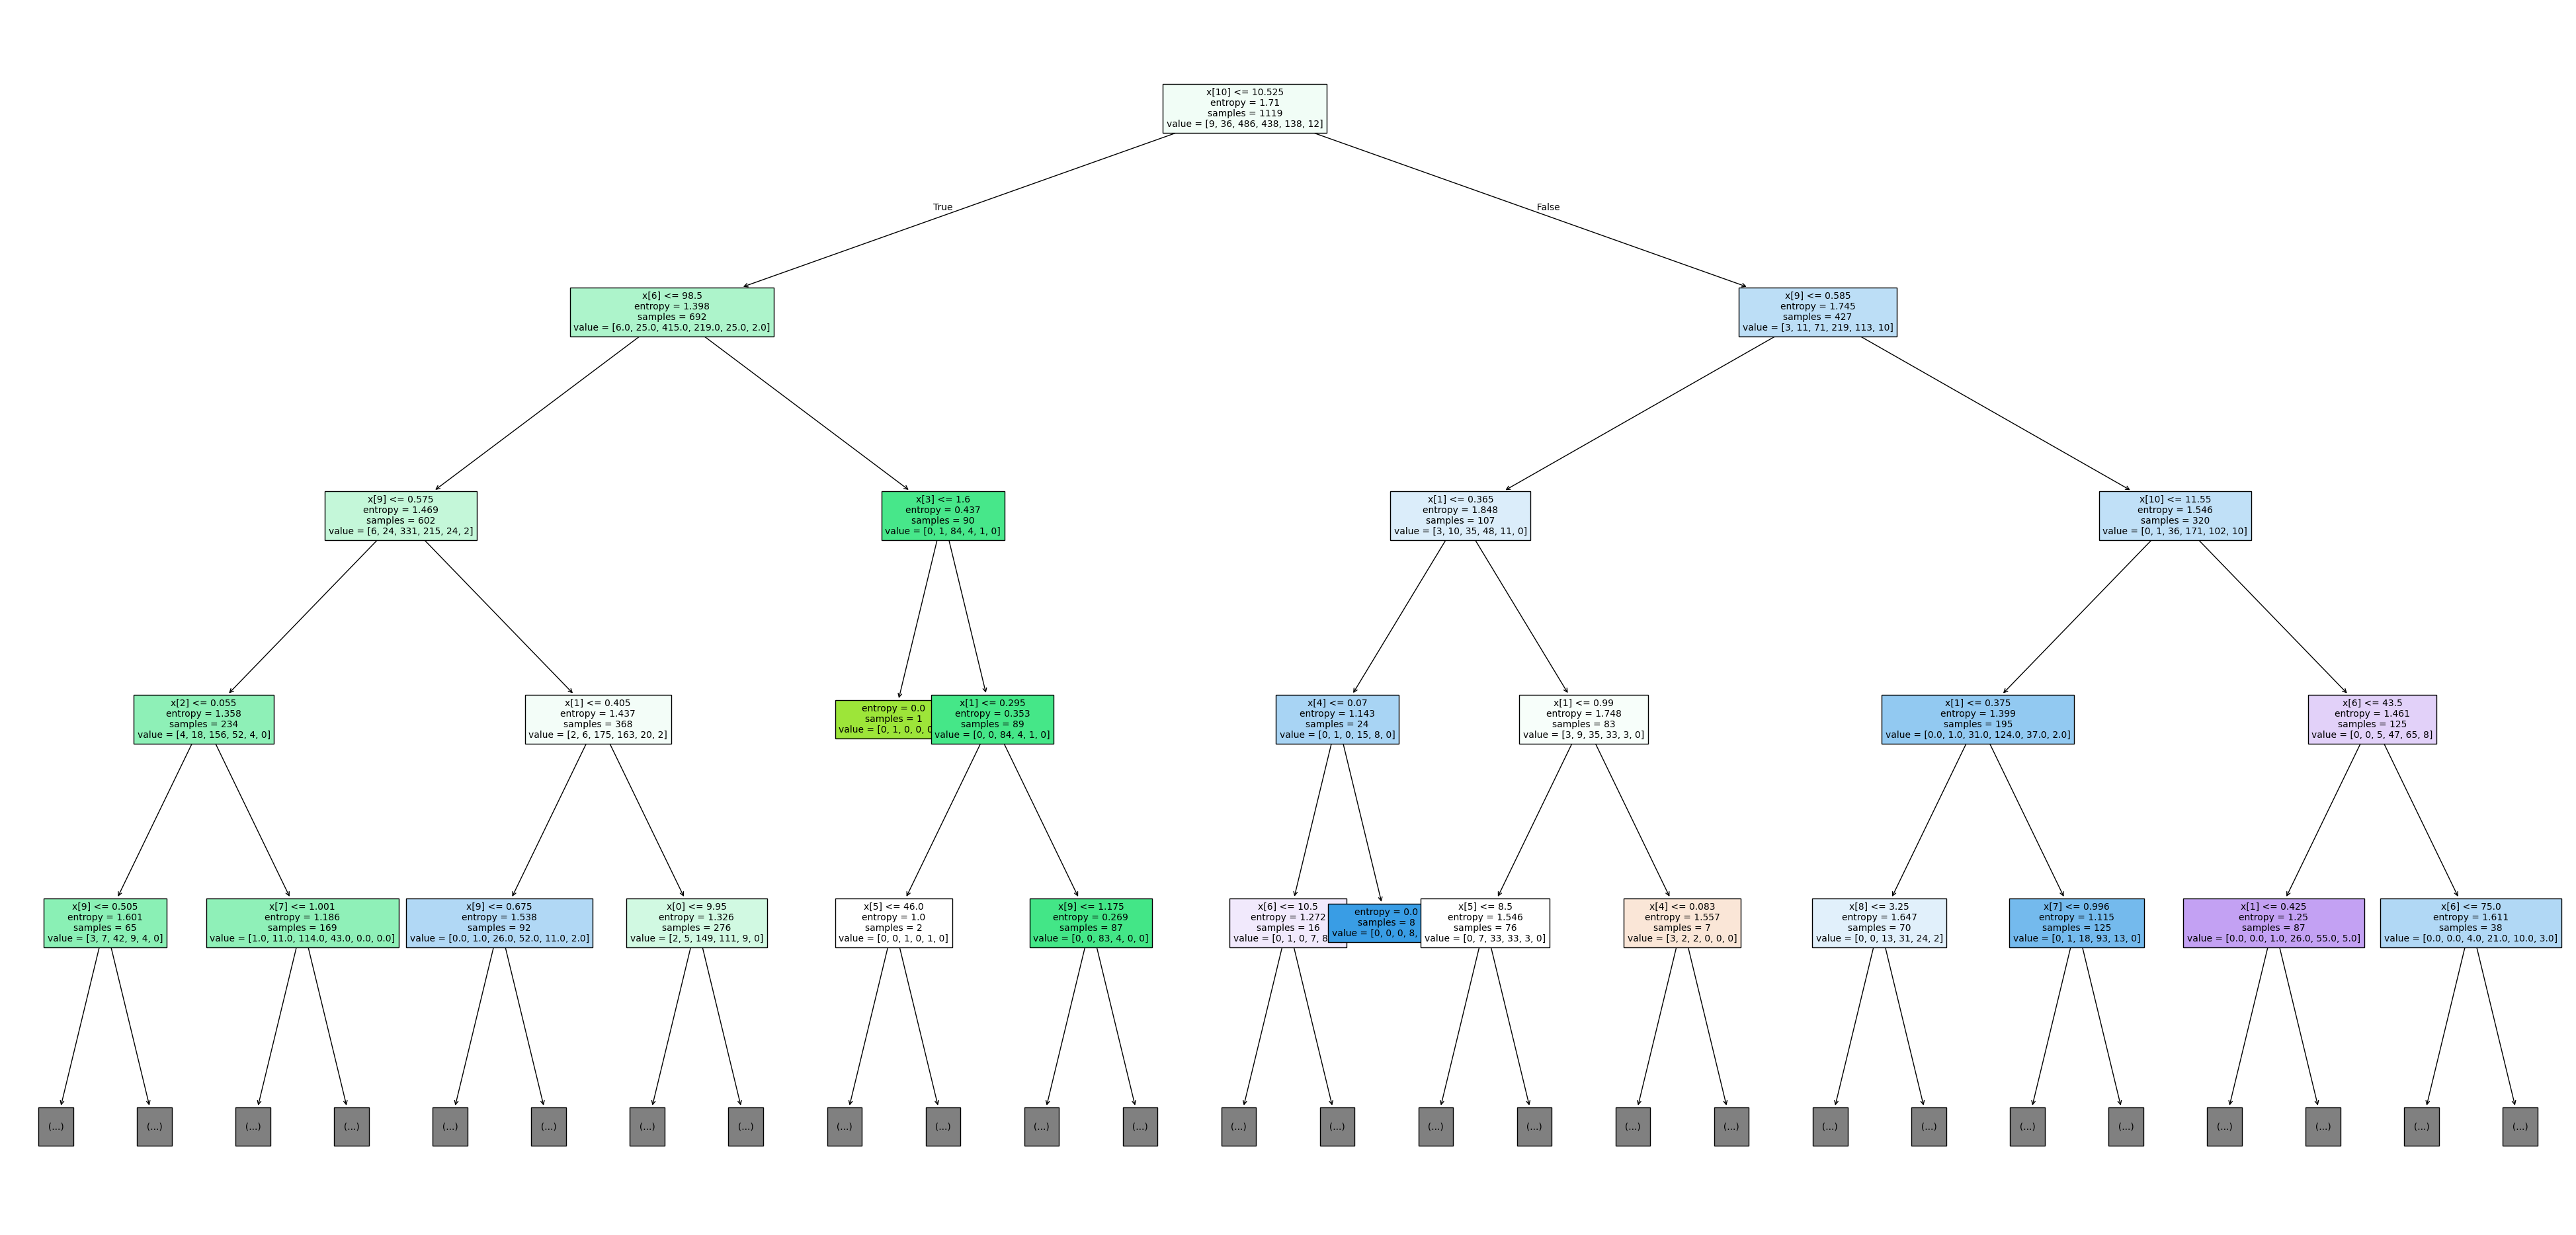

In [7]:
print("Lê Anh Pha - 6451071056")

clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf.fit(X_train, y_train)

tree_pred = clf.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:\n", metrics.classification_report(y_test, tree_pred, zero_division=0))

tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(10, 10))
sns.heatmap(tree_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (ID3) Accuracy Score: {0}'.format(tree_score), size=15)
plt.show()

fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf, filled=True, fontsize=10, max_depth=4)   # max_depth=4 chỉ để hiển thị cho đọc được
plt.savefig('decision_tree_id3', dpi=100)
plt.show()

Câu 8: Cây CART

Lê Anh Pha - 6451071056
Accuracy: 0.5625
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.64      0.62      0.63       195
           6       0.57      0.58      0.57       200
           7       0.45      0.49      0.47        61
           8       0.33      0.33      0.33         6

    accuracy                           0.56       480
   macro avg       0.34      0.35      0.35       480
weighted avg       0.56      0.56      0.56       480



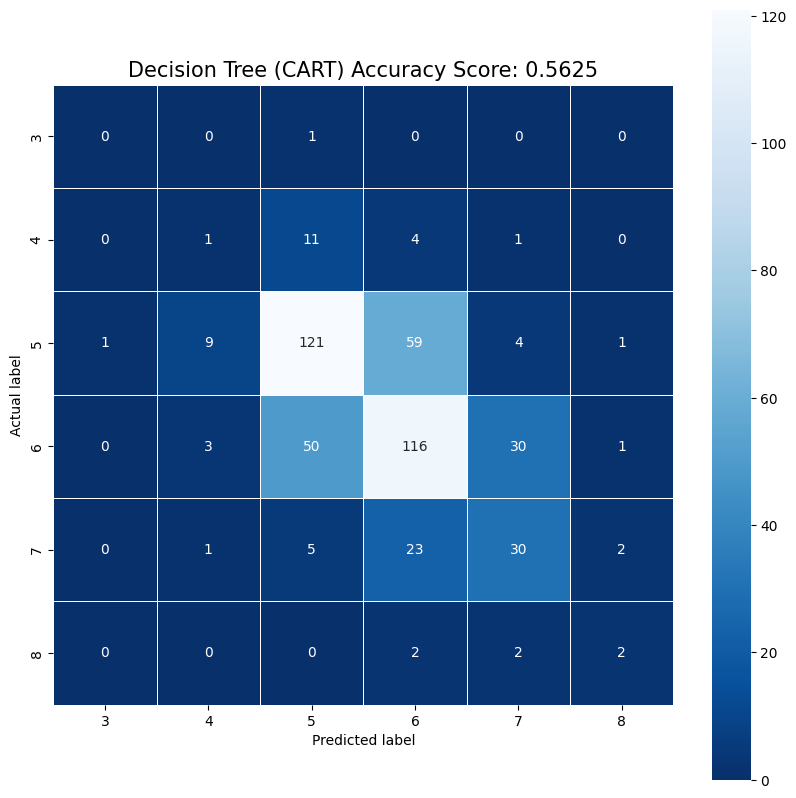

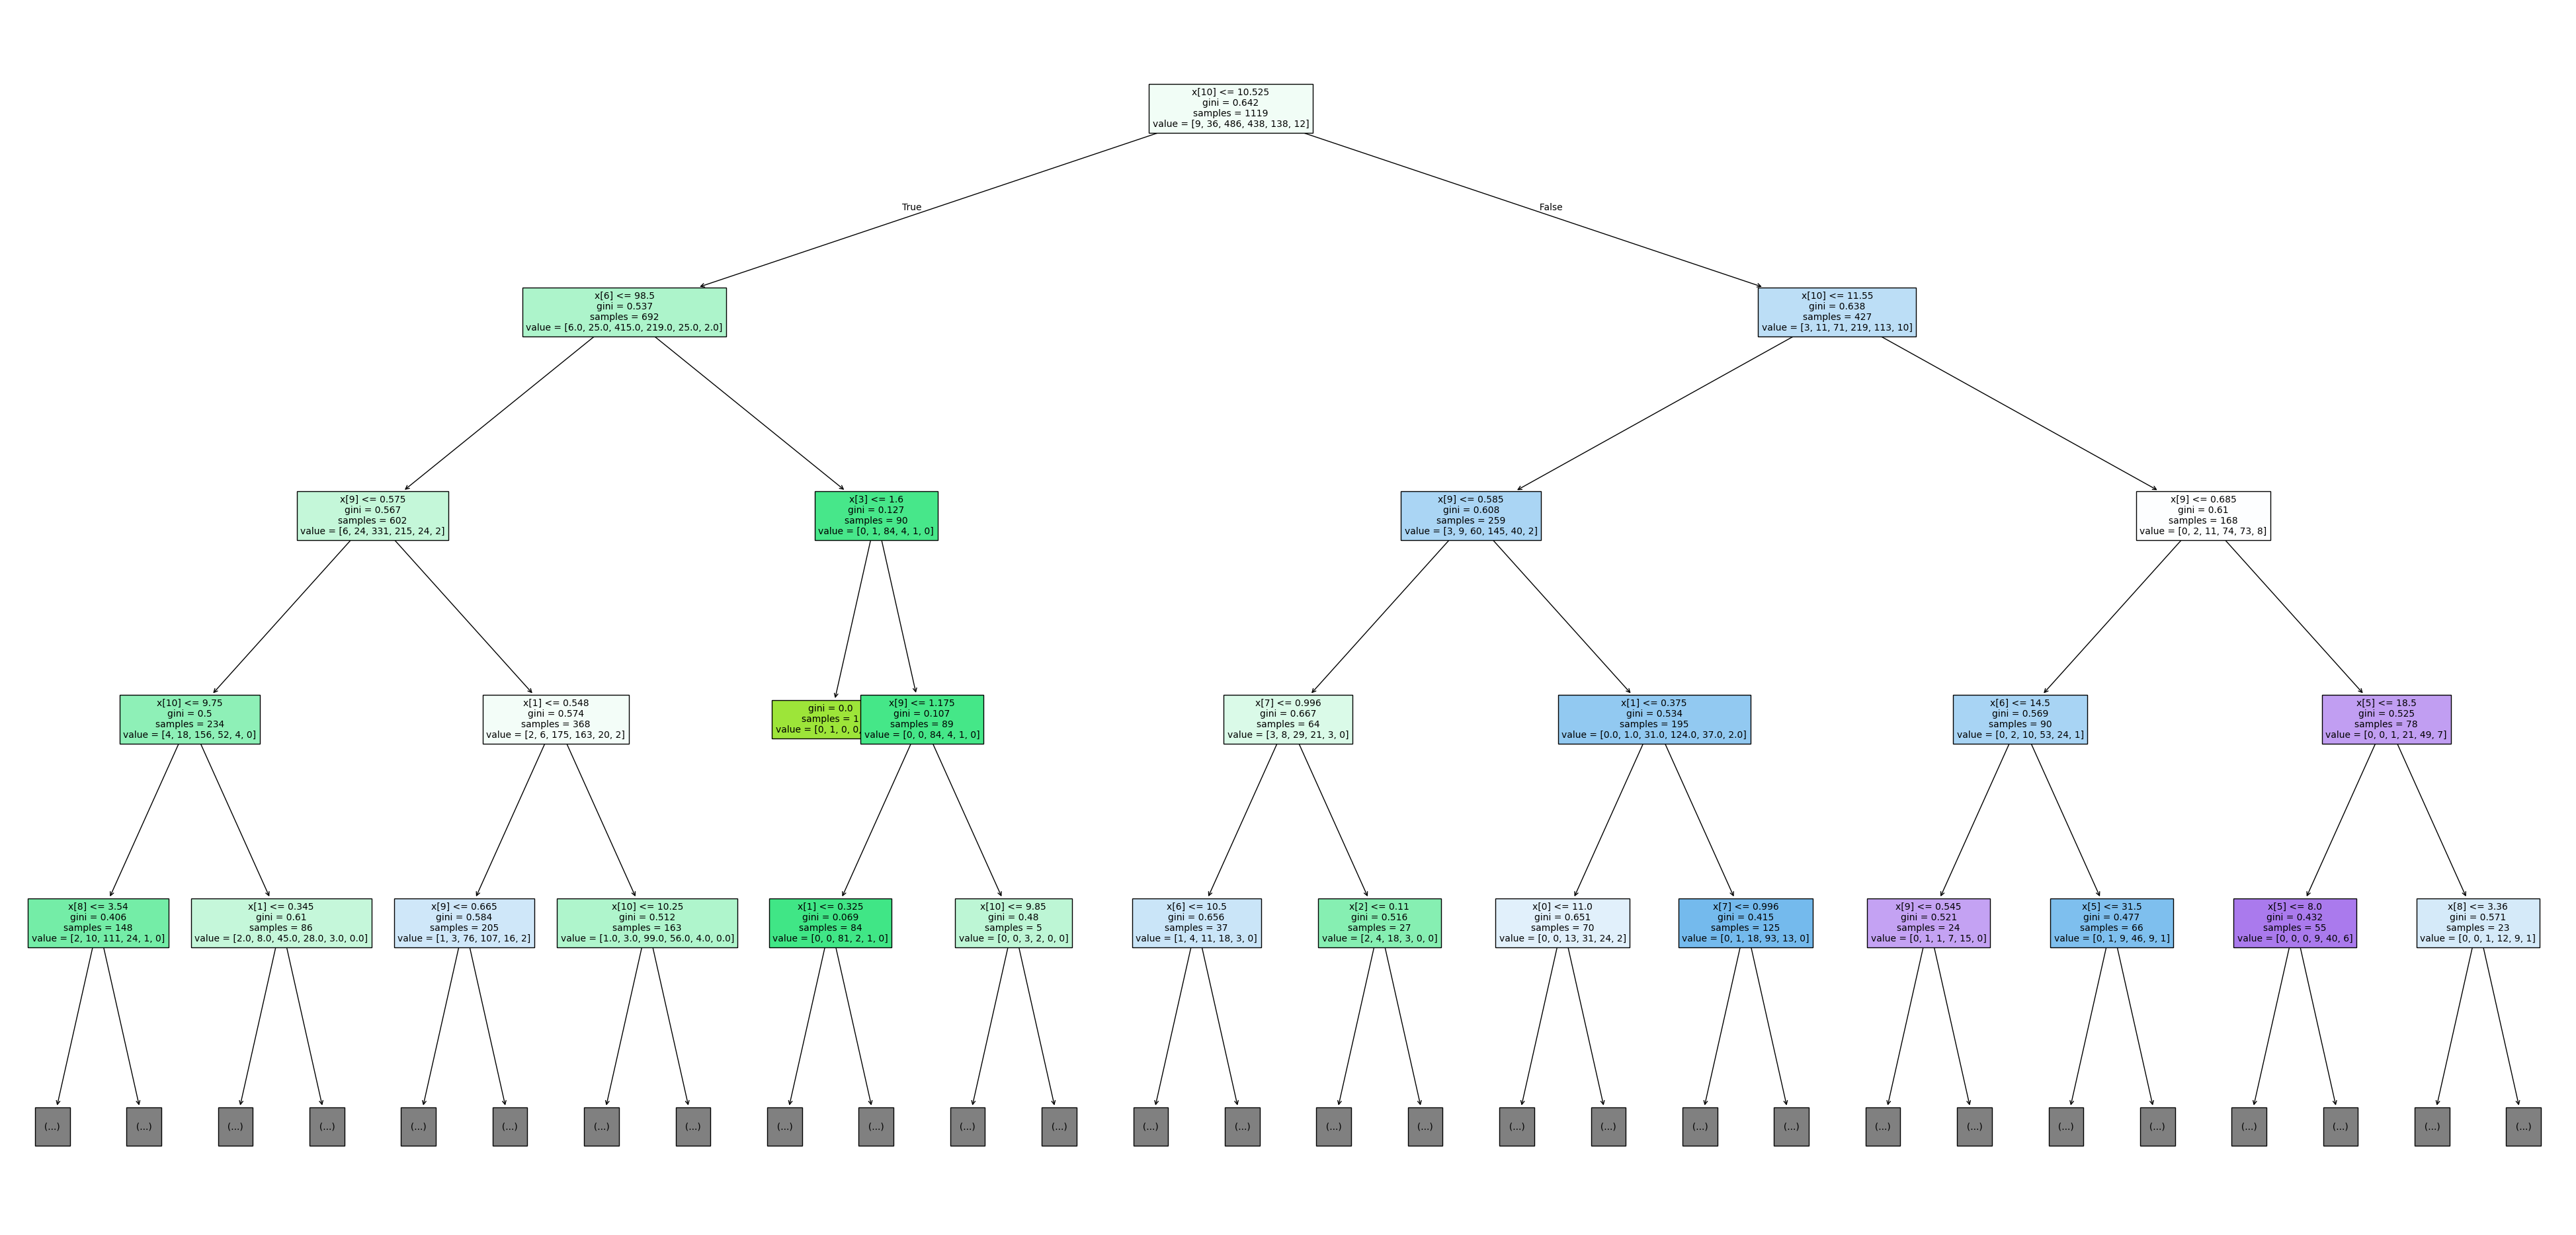

In [8]:
print("Lê Anh Pha - 6451071056")

clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred, zero_division=0))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(10, 10))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (CART) Accuracy Score: {0}'.format(cart_score), size=15)
plt.show()

fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_cart, filled=True, fontsize=10, max_depth=4)
plt.savefig('decision_tree_cart', dpi=100)
plt.show()

Câu 9: Naive Bayes

Lê Anh Pha - 6451071056
Accuracy: 0.5416666666666666
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



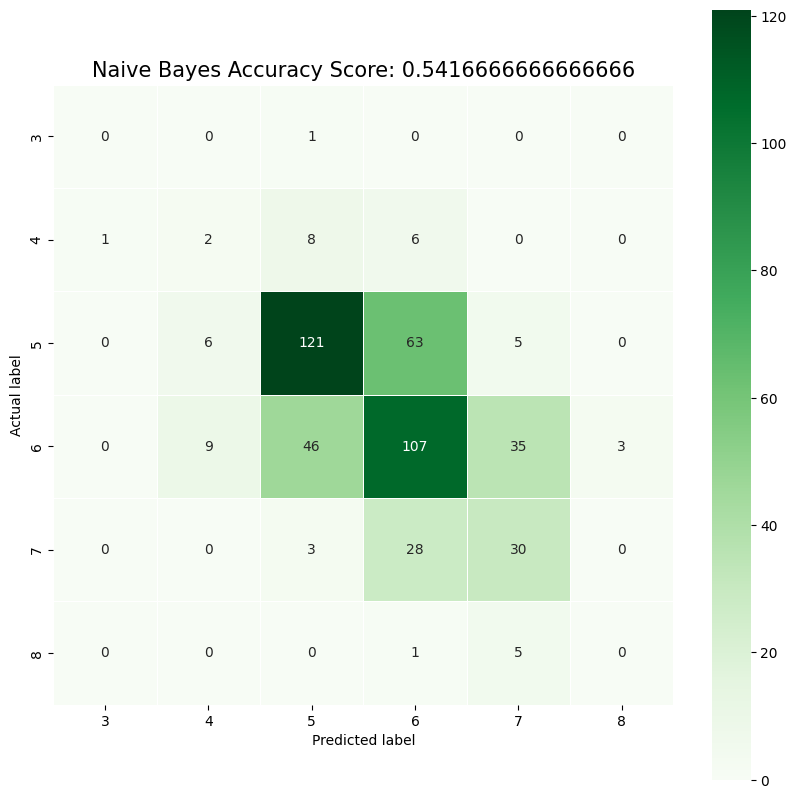

In [9]:
print("Lê Anh Pha - 6451071056")

gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred, zero_division=0))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(10, 10))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Naive Bayes Accuracy Score: {0}'.format(bayes_score), size=15)
plt.show()

Câu 10: So sánh các mô hình

In [10]:
print("Lê Anh Pha - 6451071056")

preds = {'ID3 (entropy)': tree_pred, 'CART (gini)': cart_pred, 'Naive Bayes': bayes_pred}
summary = pd.DataFrame({
    'Mô hình': list(preds.keys()),
    'Accuracy': [metrics.accuracy_score(y_test, p) for p in preds.values()],
    'Precision (weighted)': [metrics.precision_score(y_test, p, average='weighted', zero_division=0) for p in preds.values()],
    'Recall (weighted)': [metrics.recall_score(y_test, p, average='weighted', zero_division=0) for p in preds.values()],
    'F1 (weighted)': [metrics.f1_score(y_test, p, average='weighted', zero_division=0) for p in preds.values()],
})
summary

Lê Anh Pha - 6451071056


,Mô hình,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted)
0,ID3 (entropy),0.583333,0.594097,0.583333,0.588259
1,CART (gini),0.562500,0.561997,0.562500,0.561986
2,Naive Bayes,0.541667,0.547096,0.541667,0.543265
